# How routing internally works in pandaict
*Jan Ringelstein*

This notebook gives some in-depth background information on how routing works in pandaict, and which considerations are behind it. In order to calculate the data volume or needed bandwidth for the links in the network, we need to define how information items are routed through the network. Generally, we can not assume that there is exactly one possible route for every connection, but in meshed networks there might be multiple alternatives. The routing problem is to determine which one of these is taken. In general, pandaict is using the **NXGraph** python library to implement this. 

As example, we consider the following network with one connection. 

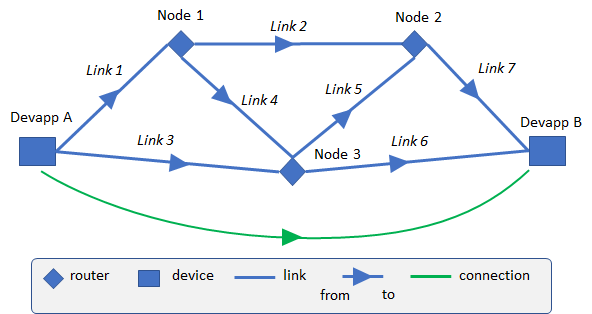

Let's assume that devapp A (an app that is running on device A) wants to send information items on a regular basis to devapp B. All the links support the used protocol. Even for that simple example, there are (at least) six options for routing the items (if we don't allow looping). Now, the data traffic over each link obviously depends on how many items take which of these routes, so we need to define that in order to calculate it. 
An important point to note is that not only the nodes are involved in the routing, but also devices - in this case, app A first needs to decide which of the two links is used to send the item over. So, routing must include devices and nodes. 

# General approaches to routing

Generally, one may consider two basic types of routing approaches: "static" and "dynamic". Static in this context means that for each connection, a single route is selected based on invariable link characteristics (e.g. latency) and used for all information items. Dynamic means that the route is defined for each information item separately, thus may be different from one item to the other. So that in effect, a certain percentage of the items uses route 1, 2, 3 and so on. In addition to that, routing may be "local" or "global". Local means that when an information item arrives at a node, the node decides the link to send it out based on its local knowledge only. Global means that there is an all-knowing entity that optimally routes the items through the network. It's easy to see that those may lead to different results. 

This classification is useful since certain routing styles may be difficult to consider in pandaict: 
- Static global routing is quite easy to accomplish using NXGraph "multidigraphs" (a graph with bidirectional edges) with shortest path calculation and proper edge weigths 
- Static local routing is fairly easy because the route can simply be determined once by hopping through the network. The main complication may be that one needs to find a way to avoid item looping without creating deadlocks.
- Dynamic global or local routing does not seem doable unless one would do a timeseries simulation. But in some cases, it should be possible to calculate statistical values (i.e. as mentioned above: this percentage of info items takes route 1, this takes route 2 etc). The fallacy here is that according assumptions must be practically feasible, such that a routing algorithm exists that practically produces this result.

In literature, dynamic routing is also called "adaptive" and static routing "non-adaptive" [2,4]. Global may be called "centralized" and local "decentralized"; also in addition to these two, "isolated" is mentioned, meaning that nodes don't use any information about other nodes or links for routing [2,3]. In [3], the latter classification is only used for static routing. Also, [3] mentions "hybrid routing" as a combination of static and dynamic routing. 

The following table lists different routing algorithms that came out of brainstorming and literature [1][2][3].


| Routing algorithm | Principle | Class | Origin |
|---|---|---|---|
|Random|Outgoing items are sent over a randomly selected link*|Static isolated|Brainstorming|
|Flooding|Outgoing items are sent over all links*|Static isolated|Literature|
|Hot Potato|Outgoing items are sent over the first link that is currently available*|Dynamic isolated|Literature|
|Round-robin|Outgoing items are sent over the next link in a round-robin fashion*|Dynamic isolated|Literature|
|Dimension ordered|Nodes are assigned coordinates in a 2D or 3D mesh. Outgoing items are sent along (x,y,(z)) dimensions until coordinates match|Static local|Literature [1]|
|Backward learning||Dynamic isolated|Literature|
|Lowest link length|Outgoing items are sent over the link with the lowest length*|Static local|Brainstorming|
|Lowest total link length|Outgoing items are sent over the link that is on the shortest-length path to the target|Static global|Brainstorming|
|Lowest static latency (local or global)|Outgoing items are sent over the link with the lowest latency*|Static local or global|Brainstorming|
|Lowest dynamic latency (local or global)|Outgoing items are sent over the link with the lowest currently measured latency*|Dynamic local or global|Brainstorming|
|Lowest total latency (static or dynamic, global)|Outgoing items are sent over the link that is on the lowest-total latency path to the target*|Dynamic or static global|Literature|
|Highest remaining bandwidth (local or global)|Outgoing items are sent over the link with the lowest currently measured traffic*|Dynamic global or local|Brainstorming|
|Load Balanced|Outgoing items are sent such that the link bandwidth usage (loading) is evenly and optimally distributed over all links|Dynamic global|Brainstorming|
|Energy efficient|Items are routed such that the total transmission energy expenditure is minimized|Static or Dynamic global|Literature [1]|

(*) except the one they arrived on

Notes: the shortest-path algorithm (Djikstra or Bellman-Ford) often mentioned in literature [1] is not listed, but is typically used to implement the global approaches from the list. E.g. for Lowest static or dynamic latency, Djikstra may be used if latencies are used as graph edge weights. 
The "Oblivious routing" mentioned in [1] applies to several static algorithms in the list, e.g. Balanced. Lowest total link length and Lowest total latency are examples for "Distance Vector Routing" [1]. Also in [1], "Link-state routing" is mentioned as an algorithm where routers measure the cost of reaching its direct neighbours (i.e. latency or other), and share that information between each other so that each router can construct an up-to-date, complete model of the network topology. Thus, each router can e.g. Djikstra to calculate the shortest path for each information item, and route it accordingly. This is essentially an implementation of Lowest total latency or link length in a local fashion. Still [1] mentions "Multipath routing", where info items are routed over multiple possible routes calculated by an approach from the list. 



# Link usage probability tables

The idea for pandaict routing was to enable multiple routing methods: albeit only one might be implemented at the start, the tool should support adding others. From the previous considerations, we see that for every pandaict connection there may be multiple possible routes. The decision which one to take depends on the routing algorithm. In some cases, the same route is taken for all information items. In a more general case, a subset of the possible routes is used, and each information item uses one of them with certain probability. We assume the probabilities stay fixed until the routing algorithm or the network topology is changed. Also, probabilities for a single connection may add up to more than 100% in the case of messages being copied. 

This consideration led to a data structure to store this information and a method to calculate it. The data structure is not a classic routing table, though; such a table would relate to one specific node (router) and e.g. say "If my neighbour node N1 sends me an information item that is originating from A and addressed to B, I always send it to my other neighbour N2". Instead, the needed data structure should store which physical links are used with which probability for a given connection, reflecting the different routes information items may take. We call this data structure a **Link usage probability table** or **LUP table**. It is not enough if such table contains link usage probabilities only, because e.g. calculation of average latencies needs adding up latencies over the various routes. Hence, the LUP table also retains information about which routes are possible. Also, it always refers to a unidirectional connection and respects the existence of asymmetrical links. Furthermore, some routing algorithms (e.g. flooding) produce information items transmitted over links although they cannot reach their destination. 

These considerations lead to the following structure:

LUP table for connection c with reference to graphics above, for a random-type routing algorithm (nodes that can not directly reach the receiver send info items over a randomly chosen outgoing link)

|Route No.|Direction (1)|Leads to receiver (2)|Share of info items taking this route (3)|Route Links and directions (4)|
|---|---|---|---|---|
|1|d|Yes|25%|1d-2d-7d|
|2|d|Yes|25%|1d-4d-6d|
|3|d|Yes|50%|3d-6d|

(1) With reference to from->to directions indicated in the graphic. "d" means "downstream" and indicates the from->to direction, "u" means "upstream" and indicates to->from. <br>
(2) States if information items taking this route reach their receiver app. In case of e.g. flooding, this is not the case for all "routes". <br> 
(3) This equals the probability of a single information item taking this route <br> 
(4) This gives the links that are part of the route, in the order the items are transmitted, together with the information in which direction of the link the transmission takes place. "d" and "u" indicate this as in (1). 

Note 1: An LUP table may or may not contain all possible routes that lead to the receiver. Routes that are used with 0% probability do usually not appear in the table. Furthermore, the table needs to be re-calculated if the network topology changes, e.g. one of the involved nodes or links becomes unavailable.

Note 2: It appears that although a specific link may appear in multiple lines of the table because it is part of different routes, the attached probabilities ("Share of info items taking this route") in these lines may not add up to more than 100%, unless the routing algorithm allows for re-sending information items over the same link 

Note 3: It should be possible to also use LUP tables for routing algorithms that do not explicitely calculate routes, e.g. flooding or random routing. However in these cases, the tables may become large and rather inefficient; e.g. for random routing and the example given above, one ends up with a decision tree with 4 "routes" that don't deliver the message to the receiver, and 7 routes that deliver. The first 4 routes may be summarized to a single "non-delivering" route, but this loads different links to different shares / probabilities, which is not storable if the data structure looks like the table. Whereas the 7 "delivering" routes can not be summarized because they use different links in different directions, so they also need to be stored explicitely if one wants to retain the information needed for latency and reliability calculation. So, with the proposed table structure, all 11 "routes" need to be explicitely stored. This could be made more efficient for some networks by directly storing the decision tree, but for the given example it seems hard to come up with a more efficient data structure. 

# Literature

[1] X. Ma: A summary of the routing algorithm and their optimization,performance, https://arxiv.org/html/2402.15749v1

[2] N. Kaur: Introduction of Routing and its types, Int. Journ. of Computer Trends and Technolo, Vol. 62 No. 2, August 2018

[3] Geeksforgeeks: Difference between Static and Dynamic Routing, https://www.geeksforgeeks.org/difference-between-static-and-dynamic-routing/

[4] Geeksforgeeks: Classification of Routing Algorithms, https://www.geeksforgeeks.org/classification-of-routing-algorithms/